In [3]:
import os
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

SEED = 26006
rng = np.random.default_rng(SEED)

np.random.seed(SEED)
print("Seed:", SEED)

Seed: 26006


## 1. Load dataset and make the fixed split
Olivetti has 40 identities, 10 images per identity, and each image is 64×64. We use 6 training, 2 validation, and 2 test images per identity: 240/80/80 total. The split is saved so every experiment uses the same images.

In [4]:
# If you already have `olivetti_faces` loaded in your notebook, this works as-is.
olivetti_faces = fetch_olivetti_faces(shuffle=False)
X_all = olivetti_faces.data.astype(np.float32)
y_all = olivetti_faces.target.astype(int)

print("X shape:", X_all.shape)
print("Number of identities:", len(np.unique(y_all)))

split_file = "olivetti_split_seed_26006.npz"

if os.path.exists(split_file):
    saved = np.load(split_file)
    train_idx = saved["train_idx"]
    val_idx = saved["val_idx"]
    test_idx = saved["test_idx"]
else:
    split_rng = np.random.default_rng(SEED)
    train_idx, val_idx, test_idx = [], [], []
    for identity in range(40):
        indices = np.where(y_all == identity)[0]
        split_rng.shuffle(indices)
        train_idx.extend(indices[:6])
        val_idx.extend(indices[6:8])
        test_idx.extend(indices[8:10])
    train_idx = np.array(train_idx)
    val_idx = np.array(val_idx)
    test_idx = np.array(test_idx)
    np.savez(split_file, train_idx=train_idx, val_idx=val_idx, test_idx=test_idx)

Xtr, ytr = X_all[train_idx], y_all[train_idx]
Xval, yval = X_all[val_idx], y_all[val_idx]
Xte, yte = X_all[test_idx], y_all[test_idx]

print("Train:", Xtr.shape, "Validation:", Xval.shape, "Test:", Xte.shape)
assert len(train_idx) == 240 and len(val_idx) == 80 and len(test_idx) == 80

X shape: (400, 4096)
Number of identities: 40
Train: (240, 4096) Validation: (80, 4096) Test: (80, 4096)


## 2. Create the masked test set
The assignment says to zero the centered 16×16 block at rows 24–39 and columns 24–39. Training and validation remain clean.

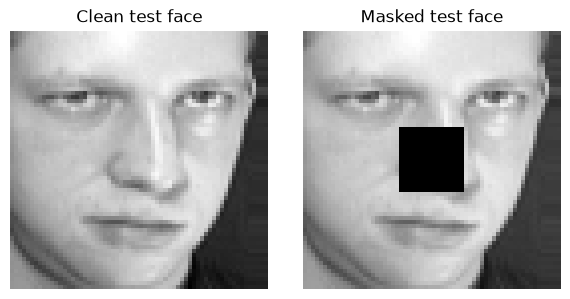

In [5]:
def mask_faces(X):
    images = X.reshape(-1, 64, 64).copy()
    images[:, 24:40, 24:40] = 0.0
    return images.reshape(-1, 4096)

Xte_masked = mask_faces(Xte)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(Xte[0].reshape(64, 64), cmap="gray")
axes[0].set_title("Clean test face")
axes[1].imshow(Xte_masked[0].reshape(64, 64), cmap="gray")
axes[1].set_title("Masked test face")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

# Q1. Decision-tree baseline and bagging from scratch

## Q1(a) Select one tree using validation accuracy only
The selection grid is depth `{2, 4, 8, None}` and minimum leaf size `{1, 2, 4}`. After selecting the best setting, freeze it for the remaining experiments.

In [7]:

tree_results = []

for depth in [2, 4, 8, None]:
    for leaf in [1, 2, 4]:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=SEED
        )

        start = time.time()
        model.fit(Xtr, ytr)
        elapsed = time.time() - start

        train_acc = accuracy_score(ytr, model.predict(Xtr))
        val_acc = accuracy_score(yval, model.predict(Xval))

        tree_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf,
            "train_accuracy": train_acc,
            "validation_accuracy": val_acc,
            "fit_seconds": elapsed
        })

tree_results = pd.DataFrame(tree_results).sort_values(
    ["validation_accuracy", "max_depth", "min_samples_leaf"],
    ascending=[False, True, True],
    na_position="last"
)

display(tree_results)

# Select the best configuration
best_row = tree_results.iloc[0]

BEST_DEPTH = best_row["max_depth"]
BEST_LEAF = int(best_row["min_samples_leaf"])

# Convert NaN back to None
if pd.isna(BEST_DEPTH):
    BEST_DEPTH = None
else:
    BEST_DEPTH = int(BEST_DEPTH)

print("Frozen setting:", BEST_DEPTH, BEST_LEAF)

# Train the selected decision tree
tree = DecisionTreeClassifier(
    max_depth=BEST_DEPTH,
    min_samples_leaf=BEST_LEAF,
    random_state=SEED
)

tree.fit(Xtr, ytr)

tree_train_acc = accuracy_score(ytr, tree.predict(Xtr))
tree_val_acc = accuracy_score(yval, tree.predict(Xval))
tree_test_acc = accuracy_score(yte, tree.predict(Xte))

print(f"Train accuracy: {tree_train_acc:.4f}")
print(f"Validation accuracy: {tree_val_acc:.4f}")
print(f"Clean test accuracy: {tree_test_acc:.4f}")


,max_depth,min_samples_leaf,train_accuracy,validation_accuracy,fit_seconds
10,NaN,2,0.970833,0.5750,3.625457
9,NaN,1,1.000000,0.5625,3.658485
11,NaN,4,0.962500,0.5250,3.478923
6,8.0,1,0.250000,0.1750,1.532720
7,8.0,2,0.250000,0.1750,1.499421
8,8.0,4,0.250000,0.1750,1.506367
3,4.0,1,0.125000,0.0750,0.777689
4,4.0,2,0.125000,0.0750,0.771659
5,4.0,4,0.125000,0.0750,0.765704
0,2.0,1,0.075000,0.0375,0.462772


Frozen setting: None 2
Train accuracy: 0.9708
Validation accuracy: 0.5750
Clean test accuracy: 0.5375


## Q1(b) Implement bootstrap aggregation
Each tree gets a bootstrap sample of size 240 drawn with replacement from the training set. Out-of-bag (OOB) accuracy uses only training examples that were not selected for that tree.

In [ ]:
def fit_bagging(X, y, n_trees, max_depth, min_samples_leaf, seed=SEED):
    local_rng = np.random.default_rng(seed)
    models = []
    boot_indices = []
    oob_indices = []
    n = len(y)

    for b in range(n_trees):
        boot = local_rng.integers(0, n, size=n)
        in_bag = np.zeros(n, dtype=bool)
        in_bag[boot] = True
        oob = np.where(~in_bag)[0]

        model = DecisionTreeClassifier(
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=seed + b
        )
        model.fit(X[boot], y[boot])
        models.append(model)
        boot_indices.append(boot)
        oob_indices.append(oob)

    return models, boot_indices, oob_indices

def ensemble_predictions(models, X):
    return np.array([model.predict(X) for model in models]).T

def majority_vote(predictions):
    # predictions shape: (n_examples, n_trees)
    out = []
    for row in predictions:
        labels, counts = np.unique(row, return_counts=True)
        out.append(labels[np.argmax(counts)])
    return np.array(out)

def vote_statistics(predictions, classes):
    # Predictions: examples x trees. Return winning fraction, runner-up fraction,
    # and winning-minus-runner-up vote margin for each example.
    fractions = np.zeros((predictions.shape[0], len(classes)))
    class_to_col = {c: j for j, c in enumerate(classes)}
    for i, row in enumerate(predictions):
        for label in row:
            fractions[i, class_to_col[label]] += 1
        fractions[i] /= len(row)
    sorted_votes = np.sort(fractions, axis=1)
    margin = sorted_votes[:, -1] - sorted_votes[:, -2]
    confidence = sorted_votes[:, -1]
    return confidence, margin, fractions

B_VALUES = [1, 5, 10, 25, 50, 100, 200]
bag_models_by_B = {}
bag_rows = []

for B in B_VALUES:
    start = time.time()
    models, boots, oobs = fit_bagging(
        Xtr, ytr, B, BEST_DEPTH, BEST_LEAF, seed=SEED + B
    )
    pred_train = ensemble_predictions(models, Xtr)
    pred_val = ensemble_predictions(models, Xval)
    pred_test = ensemble_predictions(models, Xte)

    train_acc = accuracy_score(ytr, majority_vote(pred_train))
    val_acc = accuracy_score(yval, majority_vote(pred_val))
    test_acc = accuracy_score(yte, majority_vote(pred_test))

    oob_true, oob_pred = [], []
    for i in range(len(ytr)):
        votes = []
        for model, oob in zip(models, oobs):
            if i in oob:
                votes.append(model.predict(Xtr[i:i+1])[0])
        if votes:
            oob_true.append(ytr[i])
            oob_pred.append(majority_vote(np.array(votes).reshape(1, -1))[0])

    oob_acc = accuracy_score(oob_true, oob_pred) if oob_true else np.nan
    bag_models_by_B[B] = models
    bag_rows.append({
        "B": B,
        "train_accuracy": train_acc,
        "validation_accuracy": val_acc,
        "clean_test_accuracy": test_acc,
        "oob_accuracy": oob_acc,
        "average_distinct_examples_per_bootstrap": np.mean([len(np.unique(x)) for x in boots]),
        "training_seconds": time.time() - start
    })
    print("Finished B =", B)

bag_results = pd.DataFrame(bag_rows)
display(bag_results)

Finished B = 1
Finished B = 5
Finished B = 10
Finished B = 25
Finished B = 50
Finished B = 100


## Q1(c) OOB accuracy, pairwise disagreement and vote margin
Average pairwise disagreement is the fraction of examples on which a pair of trees predict different identities. Vote margin is the winning vote fraction minus the runner-up fraction. Use validation accuracy to select the final B.

,B,validation_accuracy,pairwise_disagreement,mean_vote_margin,mean_winning_vote_fraction
0,1,0.3750,0.000000,1.00000,1.000000
1,5,0.6250,0.811250,0.23500,0.450000
2,10,0.8125,0.790278,0.27250,0.431250
3,25,0.8625,0.788542,0.28200,0.406000
4,50,0.9000,0.795673,0.27575,0.395000
5,100,0.9000,0.779124,0.29125,0.405375
6,200,0.8875,0.788294,0.28625,0.397437


Selected B: 50


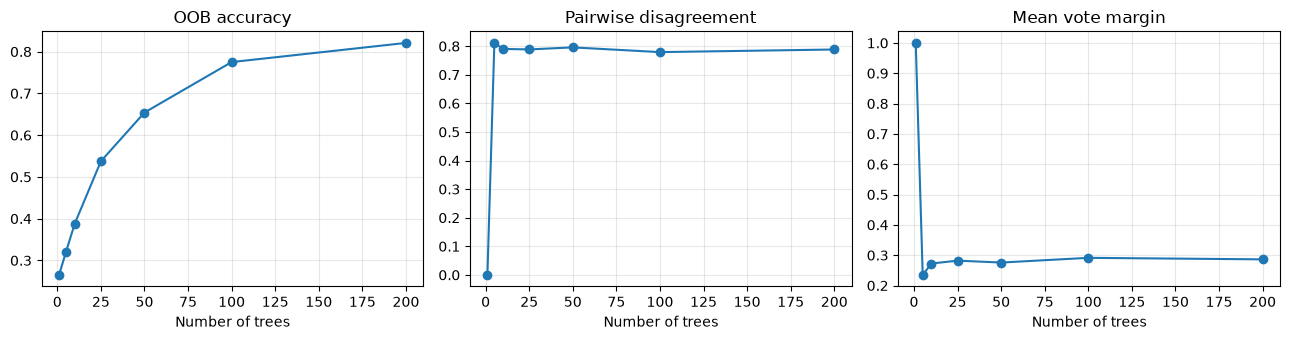

In [9]:
def pairwise_disagreement(predictions):
    n_trees = predictions.shape[1]
    if n_trees < 2:
        return 0.0
    values = []
    for i in range(n_trees):
        for j in range(i + 1, n_trees):
            values.append(np.mean(predictions[:, i] != predictions[:, j]))
    return float(np.mean(values))

disagreement_rows = []
for B in B_VALUES:
    models = bag_models_by_B[B]
    pred_val = ensemble_predictions(models, Xval)
    confidence, margin, _ = vote_statistics(pred_val, np.unique(ytr))
    disagreement_rows.append({
        "B": B,
        "validation_accuracy": accuracy_score(yval, majority_vote(pred_val)),
        "pairwise_disagreement": pairwise_disagreement(pred_val),
        "mean_vote_margin": float(np.mean(margin)),
        "mean_winning_vote_fraction": float(np.mean(confidence))
    })

disagreement_results = pd.DataFrame(disagreement_rows)
display(disagreement_results)

best_B = int(bag_results.sort_values(
    ["validation_accuracy", "B"], ascending=[False, True]
).iloc[0]["B"])
final_bag = bag_models_by_B[best_B]
print("Selected B:", best_B)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
axes[0].plot(bag_results["B"], bag_results["oob_accuracy"], marker="o")
axes[0].set_title("OOB accuracy")
axes[1].plot(disagreement_results["B"], disagreement_results["pairwise_disagreement"], marker="o")
axes[1].set_title("Pairwise disagreement")
axes[2].plot(disagreement_results["B"], disagreement_results["mean_vote_margin"], marker="o")
axes[2].set_title("Mean vote margin")
for ax in axes:
    ax.set_xlabel("Number of trees")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Q1(d) Clean versus masked test set; inspect corrected and still-wrong faces
Prediction confidence is the winning vote fraction. We identify cases where the tree is wrong but bagging is correct, and cases where both are wrong.

,model,clean_accuracy,masked_accuracy
0,Single tree,0.5375,0.3
1,Bagging B=50,0.8750,0.6


Tree wrong, bagging correct on masked set: 25
Both wrong on masked set: 31


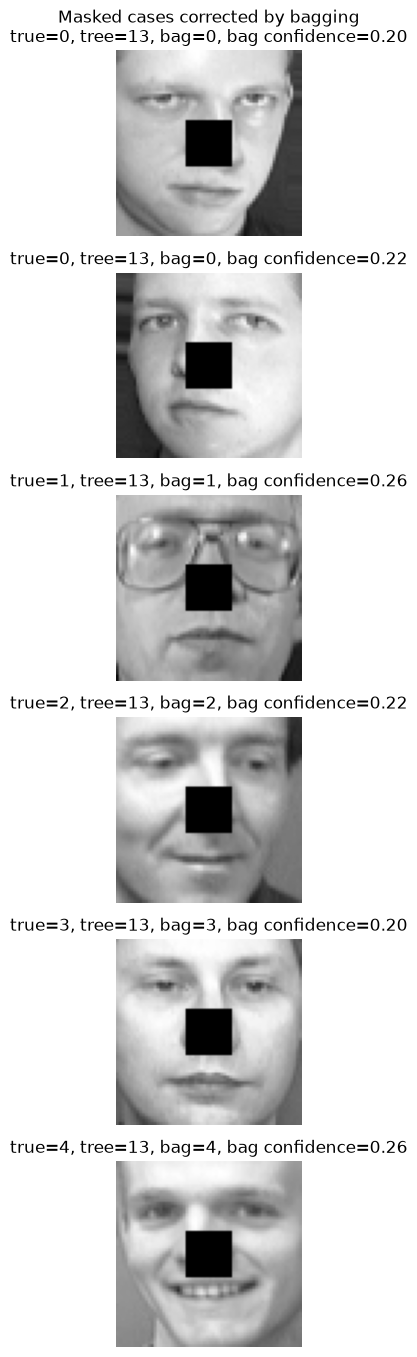

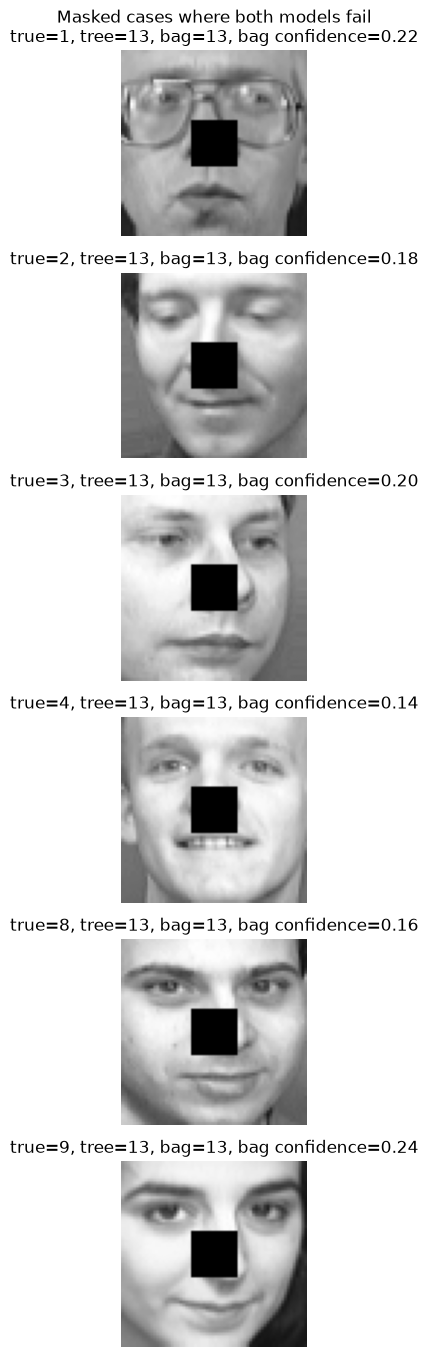

In [10]:
tree_clean_pred = tree.predict(Xte)
tree_mask_pred = tree.predict(Xte_masked)

bag_clean_votes = ensemble_predictions(final_bag, Xte)
bag_mask_votes = ensemble_predictions(final_bag, Xte_masked)
bag_clean_pred = majority_vote(bag_clean_votes)
bag_mask_pred = majority_vote(bag_mask_votes)

bag_clean_conf, bag_clean_margin, _ = vote_statistics(bag_clean_votes, np.unique(ytr))
bag_mask_conf, bag_mask_margin, _ = vote_statistics(bag_mask_votes, np.unique(ytr))

q1d_results = pd.DataFrame([
    {"model": "Single tree", "clean_accuracy": accuracy_score(yte, tree_clean_pred),
     "masked_accuracy": accuracy_score(yte, tree_mask_pred)},
    {"model": f"Bagging B={best_B}", "clean_accuracy": accuracy_score(yte, bag_clean_pred),
     "masked_accuracy": accuracy_score(yte, bag_mask_pred)}
])
display(q1d_results)

corrected = np.where((tree_mask_pred != yte) & (bag_mask_pred == yte))[0]
both_wrong = np.where((tree_mask_pred != yte) & (bag_mask_pred != yte))[0]
print("Tree wrong, bagging correct on masked set:", len(corrected))
print("Both wrong on masked set:", len(both_wrong))

def show_cases(indices, title, max_cases=6):
    indices = indices[:max_cases]
    if len(indices) == 0:
        print("No examples for:", title)
        return
    fig, axes = plt.subplots(len(indices), 1, figsize=(3, 2.3 * len(indices)))
    if len(indices) == 1:
        axes = [axes]
    for ax, i in zip(axes, indices):
        ax.imshow(Xte_masked[i].reshape(64, 64), cmap="gray")
        ax.set_title(
            f"true={yte[i]}, tree={tree_mask_pred[i]}, bag={bag_mask_pred[i]}, "
            f"bag confidence={bag_mask_conf[i]:.2f}"
        )
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_cases(corrected, "Masked cases corrected by bagging")
show_cases(both_wrong, "Masked cases where both models fail")

# Q2. Multiclass boosting from scratch (SAMME)

For K classes, the SAMME learner weight is `alpha = log((1-error)/error) + log(K-1)`. A learner with error at least `1 - 1/K` is no better than random multiclass prediction and is not accepted. Sample weights are updated after every accepted learner and normalized to sum to one.

In [11]:
class SAMME:
    def __init__(self, n_estimators=50, max_depth=1, min_samples_leaf=1, random_state=SEED):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.random_state = random_state
        self.models = []
        self.alphas = []
        self.classes_ = None
        self.history_ = []

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        K = len(self.classes_)
        n = len(y)
        weights = np.ones(n) / n
        self.models = []
        self.alphas = []
        self.history_ = []

        for b in range(self.n_estimators):
            model = DecisionTreeClassifier(
                max_depth=self.max_depth,
                min_samples_leaf=self.min_samples_leaf,
                random_state=self.random_state + b
            )
            model.fit(X, y, sample_weight=weights)
            pred = model.predict(X)
            incorrect = pred != y
            error = float(np.sum(weights * incorrect))

            # Stop if the weak learner is no better than random multiclass prediction.
            if error >= 1.0 - (1.0 / K):
                if b == 0:
                    raise ValueError("First weak learner is no better than random; change depth or seed.")
                break

            error = max(error, 1e-12)
            alpha = np.log((1.0 - error) / error) + np.log(K - 1)

            self.models.append(model)
            self.alphas.append(float(alpha))

            weights *= np.exp(alpha * incorrect)
            weights /= weights.sum()

            self.history_.append({
                "round": b + 1,
                "weighted_error": error,
                "alpha": alpha,
                "max_sample_weight": weights.max(),
                "total_sample_weight": weights.sum(),
                "training_error": np.mean(pred != y)
            })

            if error == 0:
                break

        self.alphas = np.array(self.alphas)
        return self

    def decision_function(self, X):
        scores = np.zeros((len(X), len(self.classes_)), dtype=float)
        class_to_col = {c: j for j, c in enumerate(self.classes_)}
        for model, alpha in zip(self.models, self.alphas):
            pred = model.predict(X)
            for i, label in enumerate(pred):
                scores[i, class_to_col[label]] += alpha
        return scores

    def predict(self, X):
        scores = self.decision_function(X)
        return self.classes_[np.argmax(scores, axis=1)]

    def predict_confidence(self, X):
        scores = self.decision_function(X)
        totals = scores.sum(axis=1, keepdims=True)
        totals[totals == 0] = 1.0
        normalized = scores / totals
        return normalized.max(axis=1), normalized

## Q2(a) Small three-class, ten-example demonstration
This cell manually shows one complete SAMME round: initial weights, weak predictions, weighted error, alpha, and updated weights.

In [12]:
# Small reproducible toy example with 10 samples and 3 classes
X_toy = np.array([
    [0.0, 0.0], [0.1, 0.0], [0.2, 0.1], [0.3, 0.2],
    [0.8, 0.8], [0.9, 0.7], [1.0, 0.9],
    [0.0, 1.0], [0.1, 0.9], [0.2, 0.8]
])
y_toy = np.array([0, 0, 0, 0, 1, 1, 1, 2, 2, 2])
w_toy = np.ones(len(y_toy)) / len(y_toy)

toy_learner = DecisionTreeClassifier(max_depth=1, random_state=SEED)
toy_learner.fit(X_toy, y_toy, sample_weight=w_toy)
toy_pred = toy_learner.predict(X_toy)
toy_error = np.sum(w_toy * (toy_pred != y_toy))
K_toy = len(np.unique(y_toy))
toy_alpha = np.log((1 - toy_error) / toy_error) + np.log(K_toy - 1)
w_toy_new = w_toy * np.exp(toy_alpha * (toy_pred != y_toy))
w_toy_new = w_toy_new / w_toy_new.sum()

print("Initial weights:", np.round(w_toy, 4))
print("True labels:     ", y_toy)
print("Predictions:     ", toy_pred)
print("Weighted error:", round(float(toy_error), 4))
print("Alpha:", round(float(toy_alpha), 4))
print("Updated weights:", np.round(w_toy_new, 4))
print("Updated sum:", w_toy_new.sum())

Initial weights: [0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]
True labels:      [0 0 0 0 1 1 1 2 2 2]
Predictions:      [0 0 0 0 1 1 1 1 1 1]
Weighted error: 0.3
Alpha: 1.5404
Updated weights: [0.0476 0.0476 0.0476 0.0476 0.0476 0.0476 0.0476 0.2222 0.2222 0.2222]
Updated sum: 1.0


## Q2(b) Select depth and number of rounds using clean validation accuracy
Use the specified depths and rounds. Training and validation are clean; no test data is used for model selection.

In [13]:
BOOST_DEPTHS = [1, 2, 3, 4]
BOOST_ROUNDS = [10, 25, 50, 100]
boost_results = []
boost_models = {}

for depth in BOOST_DEPTHS:
    for rounds in BOOST_ROUNDS:
        start = time.time()
        model = SAMME(
            n_estimators=rounds,
            max_depth=depth,
            min_samples_leaf=1,
            random_state=SEED
        )
        try:
            model.fit(Xtr, ytr)
            train_acc = accuracy_score(ytr, model.predict(Xtr))
            val_acc = accuracy_score(yval, model.predict(Xval))
            boost_models[(depth, rounds)] = model
            boost_results.append({
                "depth": depth, "requested_rounds": rounds,
                "accepted_rounds": len(model.models),
                "train_accuracy": train_acc,
                "validation_accuracy": val_acc,
                "training_seconds": time.time() - start
            })
            print("Finished depth, rounds:", depth, rounds)
        except ValueError as e:
            print("Skipped:", depth, rounds, e)

boost_results = pd.DataFrame(boost_results)
display(boost_results.sort_values("validation_accuracy", ascending=False))

best_boost_row = boost_results.sort_values(
    ["validation_accuracy", "requested_rounds"], ascending=[False, True]
).iloc[0]
BEST_BOOST_DEPTH = int(best_boost_row["depth"])
BEST_BOOST_ROUNDS = int(best_boost_row["requested_rounds"])
boost = boost_models[(BEST_BOOST_DEPTH, BEST_BOOST_ROUNDS)]
print("Selected SAMME model:", BEST_BOOST_DEPTH, BEST_BOOST_ROUNDS)
display(pd.DataFrame(boost.history_).head())

Finished depth, rounds: 1 10
Finished depth, rounds: 1 25
Finished depth, rounds: 1 50
Finished depth, rounds: 1 100
Finished depth, rounds: 2 10
Finished depth, rounds: 2 25
Finished depth, rounds: 2 50
Finished depth, rounds: 2 100
Finished depth, rounds: 3 10
Finished depth, rounds: 3 25
Finished depth, rounds: 3 50
Finished depth, rounds: 3 100
Finished depth, rounds: 4 10
Finished depth, rounds: 4 25
Finished depth, rounds: 4 50
Finished depth, rounds: 4 100


,depth,requested_rounds,accepted_rounds,train_accuracy,validation_accuracy,training_seconds
15,4,100,100,1.000000,0.4625,93.117990
11,3,100,100,0.687500,0.2500,60.662310
10,3,50,50,0.495833,0.2375,31.271885
7,2,100,100,0.425000,0.2250,42.615200
13,4,25,25,0.529167,0.2250,20.426127
9,3,25,25,0.404167,0.2125,15.601024
6,2,50,50,0.379167,0.1875,20.920204
12,4,10,10,0.420833,0.1750,8.246771
14,4,50,50,0.491667,0.1500,39.711765
2,1,50,50,0.229167,0.1500,10.936107


Selected SAMME model: 4 100


,round,weighted_error,alpha,max_sample_weight,total_sample_weight,training_error
0,1,0.850000,1.928961,0.004779,1.0,0.850000
1,2,0.856618,1.876085,0.005440,1.0,0.875000
2,3,0.835222,2.040465,0.006350,1.0,0.866667
3,4,0.799447,2.280721,0.007745,1.0,0.854167
4,5,0.753568,2.545831,0.010021,1.0,0.808333


## Q2(b) Inspect boosting history
Plot weighted training error, learner weight, maximum sample weight, and training error over rounds.

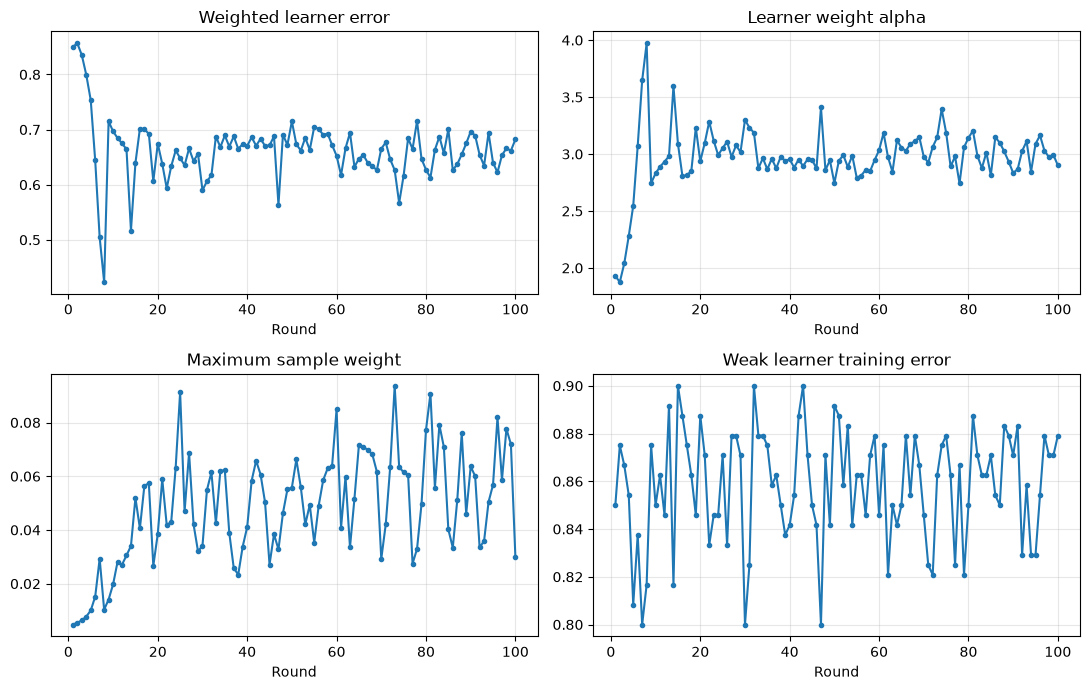

Round with largest maximum sample weight: 73
Largest sample weight: 0.09368853356247275


In [14]:
boost_history = pd.DataFrame(boost.history_)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].plot(boost_history["round"], boost_history["weighted_error"], marker=".")
axes[0, 0].set_title("Weighted learner error")
axes[0, 1].plot(boost_history["round"], boost_history["alpha"], marker=".")
axes[0, 1].set_title("Learner weight alpha")
axes[1, 0].plot(boost_history["round"], boost_history["max_sample_weight"], marker=".")
axes[1, 0].set_title("Maximum sample weight")
axes[1, 1].plot(boost_history["round"], boost_history["training_error"], marker=".")
axes[1, 1].set_title("Weak learner training error")
for ax in axes.flat:
    ax.set_xlabel("Round")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

hardest = int(np.argmax(boost_history["max_sample_weight"].to_numpy()))
print("Round with largest maximum sample weight:", hardest + 1)
print("Largest sample weight:", boost_history.iloc[hardest]["max_sample_weight"])

## Q2(c) Compare boosting and bagging with 25, 50 and 100 learners
Training time is measured on the current machine and will vary. Accuracy is measured on the same fixed clean split.

In [15]:
comparison_rows = []
for B in [25, 50, 100]:
    start = time.time()
    models, _, _ = fit_bagging(
        Xtr, ytr, B, BEST_DEPTH, BEST_LEAF, seed=SEED + 1000 + B
    )
    bag_time = time.time() - start
    bag_train = accuracy_score(ytr, majority_vote(ensemble_predictions(models, Xtr)))
    bag_val = accuracy_score(yval, majority_vote(ensemble_predictions(models, Xval)))
    bag_test = accuracy_score(yte, majority_vote(ensemble_predictions(models, Xte)))
    comparison_rows.append({
        "method": "Bagging", "learners": B,
        "train_accuracy": bag_train, "validation_accuracy": bag_val,
        "clean_test_accuracy": bag_test, "training_seconds": bag_time
    })

    start = time.time()
    boost_model = SAMME(
        n_estimators=B, max_depth=BEST_BOOST_DEPTH,
        min_samples_leaf=1, random_state=SEED
    ).fit(Xtr, ytr)
    boost_time = time.time() - start
    comparison_rows.append({
        "method": "SAMME", "learners": B,
        "train_accuracy": accuracy_score(ytr, boost_model.predict(Xtr)),
        "validation_accuracy": accuracy_score(yval, boost_model.predict(Xval)),
        "clean_test_accuracy": accuracy_score(yte, boost_model.predict(Xte)),
        "training_seconds": boost_time
    })

comparison_results = pd.DataFrame(comparison_rows)
display(comparison_results)

,method,learners,train_accuracy,validation_accuracy,clean_test_accuracy,training_seconds
0,Bagging,25,1.000000,0.8875,0.8125,72.695726
1,SAMME,25,0.529167,0.2250,0.3000,20.766669
2,Bagging,50,1.000000,0.8625,0.8000,141.138048
3,SAMME,50,0.491667,0.1500,0.1500,42.751572
4,Bagging,100,1.000000,0.9000,0.8000,282.642453
5,SAMME,100,1.000000,0.4625,0.4375,84.807182


## Q2(d) Compare all three models on clean and masked test sets
For a single tree, confidence is the fraction of training examples in the predicted leaf belonging to the predicted class. For bagging, confidence is the winning vote fraction. For SAMME, confidence is the largest normalized class score.

,model,clean_accuracy,masked_accuracy,clean_mean_confidence,masked_mean_confidence
0,Single tree,0.5375,0.30,0.981250,1.000000
1,Bagging B=50,0.8750,0.60,0.382250,0.266500
2,SAMME,0.4375,0.35,0.119394,0.119772


Bagging vs boosting disagreement count on masked test: 54


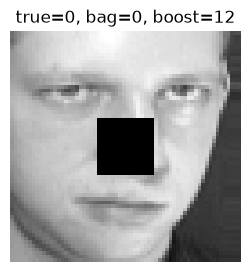

Bagging confidence: 0.2
Boosting confidence: 0.09131859516085537


In [16]:
# Single-tree leaf confidence
def tree_leaf_confidence(model, X):
    leaf_ids = model.apply(X)
    leaf_conf = {}
    for leaf in np.unique(leaf_ids):
        idx = model.apply(Xtr) == leaf
        if np.any(idx):
            _, counts = np.unique(ytr[idx], return_counts=True)
            leaf_conf[leaf] = counts.max() / counts.sum()
        else:
            leaf_conf[leaf] = 0.0
    return np.array([leaf_conf[leaf] for leaf in leaf_ids])

single_clean_conf = tree_leaf_confidence(tree, Xte)
single_mask_conf = tree_leaf_confidence(tree, Xte_masked)
boost_clean_conf, _ = boost.predict_confidence(Xte)
boost_mask_conf, _ = boost.predict_confidence(Xte_masked)

model_test_rows = [
    {"model": "Single tree", "clean_accuracy": accuracy_score(yte, tree_clean_pred),
     "masked_accuracy": accuracy_score(yte, tree_mask_pred),
     "clean_mean_confidence": np.mean(single_clean_conf),
     "masked_mean_confidence": np.mean(single_mask_conf)},
    {"model": f"Bagging B={best_B}", "clean_accuracy": accuracy_score(yte, bag_clean_pred),
     "masked_accuracy": accuracy_score(yte, bag_mask_pred),
     "clean_mean_confidence": np.mean(bag_clean_conf),
     "masked_mean_confidence": np.mean(bag_mask_conf)},
    {"model": "SAMME", "clean_accuracy": accuracy_score(yte, boost.predict(Xte)),
     "masked_accuracy": accuracy_score(yte, boost.predict(Xte_masked)),
     "clean_mean_confidence": np.mean(boost_clean_conf),
     "masked_mean_confidence": np.mean(boost_mask_conf)}
]
model_test_results = pd.DataFrame(model_test_rows)
display(model_test_results)

# Face where bagging and boosting disagree, with sample-weight history available for SAMME.
bag_mask_pred_final = bag_mask_pred
boost_mask_pred = boost.predict(Xte_masked)
disagree = np.where(bag_mask_pred_final != boost_mask_pred)[0]
print("Bagging vs boosting disagreement count on masked test:", len(disagree))
if len(disagree):
    i = int(disagree[0])
    plt.figure(figsize=(3, 3))
    plt.imshow(Xte_masked[i].reshape(64, 64), cmap="gray")
    plt.title(f"true={yte[i]}, bag={bag_mask_pred_final[i]}, boost={boost_mask_pred[i]}")
    plt.axis("off")
    plt.show()
    print("Bagging confidence:", bag_mask_conf[i])
    print("Boosting confidence:", boost_mask_conf[i])